### Exercice 9 — Machines à vecteurs de support

In [31]:
from sklearn.datasets import make_moons

from sklearn.model_selection  import train_test_split

from sklearn.svm import SVC 

from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt

import numpy as np

### Generation du dataset

In [32]:
x, y = make_moons(n_samples=400, noise=0.25, random_state=7)

### Separation du train et du test

In [33]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.3)

### Entraînement d'un SVC model 1

In [39]:
model1 = SVC(kernel="linear")

model1.fit(x_train,y_train)

model1.score(x_train,y_train)

pred_m1 = model1.predict(x_test)

model1.score(x_test,y_test)

0.825

### Entraînement d'un SVC model 2

In [43]:
model2 = SVC(kernel="rbf", gamma="scale")

model2.fit(x_train,y_train)

model2.score(x_train,y_train)

pred_m2 = model2.predict(x_test)

model2.score(x_test,y_test)

0.9083333333333333

### Visualisation des frontiere

Text(0, 0.5, 'X2')

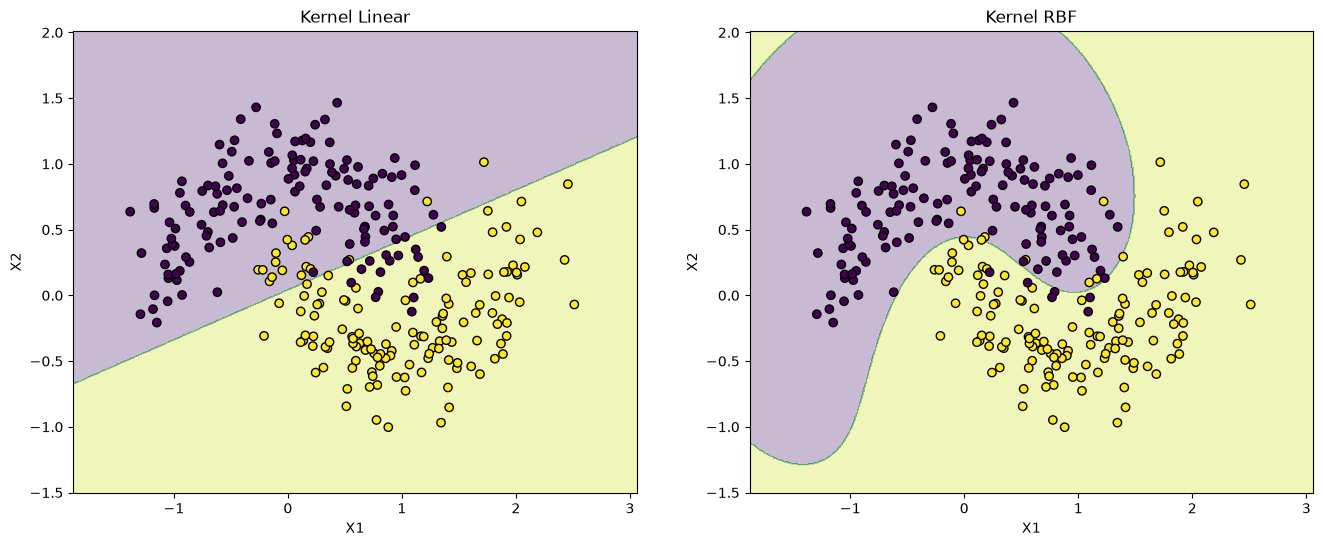

In [44]:
x_min, x_max = x[:, 0].min() - 0.5, x[:, 0].max() + 0.5

y_min, y_max = x[:, 1].min() - 0.5, x[:, 1].max() + 0.5

xx, yy = np.meshgrid(

    np.linspace(x_min, x_max, 500),

    np.linspace(y_min, y_max, 500)

)

grid = np.c_[xx.ravel(), yy.ravel()]

Z_linear = model1.predict(grid)

Z_rbf = model2.predict(grid)

Z_linear = Z_linear.reshape(xx.shape)

Z_rbf = Z_rbf.reshape(xx.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

ax[0].contourf(
    xx,
    yy,
    Z_linear,
    alpha=0.3
)

ax[0].scatter(

    x_train[:, 0],

    x_train[:, 1],

    c=y_train,

    edgecolors="black"
)

ax[0].set_title("Kernel Linear")

ax[0].set_xlabel("X1")

ax[0].set_ylabel("X2")

ax[1].contourf(

    xx,

    yy,

    Z_rbf,

    alpha=0.3

)

ax[1].scatter(

    x_train[:, 0],

    x_train[:, 1],

    c=y_train,

    edgecolors="black"
)

ax[1].set_title("Kernel RBF")

ax[1].set_xlabel("X1")

ax[1].set_ylabel("X2")


### Comparaison des accuracy score 

In [45]:
accuracy_score(pred_m1 , y_test)


0.825

In [46]:
accuracy_score(pred_m2 , y_test)

0.9083333333333333

### Faisons varier le paramètre C

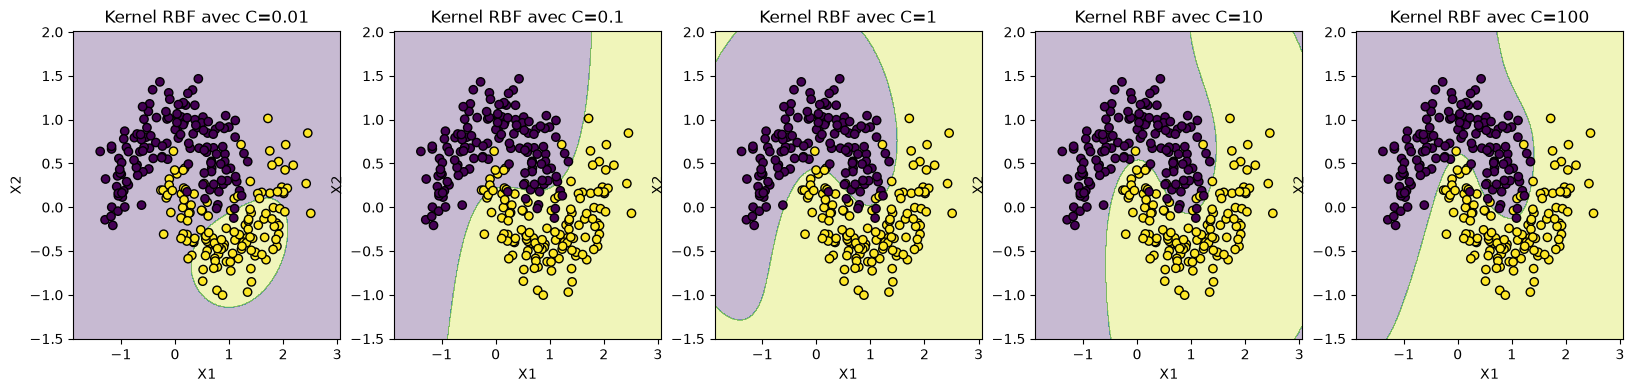

In [54]:
c_values = [0.01, 0.1, 1, 10, 100]

iter =  [i for i in range(0,5)]

fig , ax = plt.subplots(1,5,figsize=(20,4))

for i in iter :

    model = SVC(kernel="rbf", gamma="scale" , C=c_values[i])

    model.fit(x_train,y_train)

    model.score(x_train,y_train)

    pred = model.predict(x_test)

    model.score(x_test,y_test)

    Z_rbf = model.predict(grid)

    Z_rbf = Z_rbf.reshape(xx.shape)

    ax[i].contourf(

    xx,

    yy,

    Z_rbf,

    alpha=0.3
)
    ax[i].scatter(

        x_train[:, 0],

        x_train[:, 1],

        c=y_train,

        edgecolors="black"
    )

    ax[i].set_title(f"Kernel RBF avec C={c_values[i]}")

    ax[i].set_xlabel("X1")

    ax[i].set_ylabel("X2")



    


    